In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('C:/Users/user/Downloads/visual_data/nyc_temp.csv')

In [6]:
df.head()

,date,temp
0,1869-01-01,-17
1,1869-01-02,-28
2,1869-01-03,17
3,1869-01-04,28
4,1869-01-05,61


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    3650 non-null   object
 1   temp    3650 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 57.2+ KB


In [8]:
df = pd.read_csv('C:/Users/user/Downloads/visual_data/nyc_temp.csv',parse_dates=['date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3650 non-null   datetime64[ns]
 1   temp    3650 non-null   int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 57.2 KB


In [9]:
df

,date,temp
0,1869-01-01,-17
1,1869-01-02,-28
2,1869-01-03,17
3,1869-01-04,28
4,1869-01-05,61
...,...,...
3645,1878-12-27,-17
3646,1878-12-28,-11
3647,1878-12-29,39
3648,1878-12-30,0


In [10]:
df = df.set_index('date')
df.head()

,temp
date,
1869-01-01,-17
1869-01-02,-28
1869-01-03,17
1869-01-04,28
1869-01-05,61


<Axes: xlabel='date'>

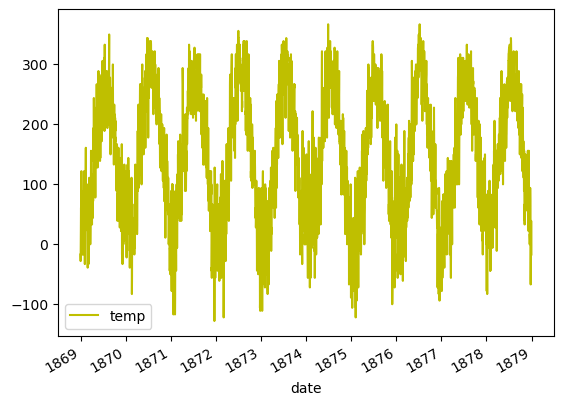

In [11]:
df.plot(color='y')

<Axes: xlabel='date'>

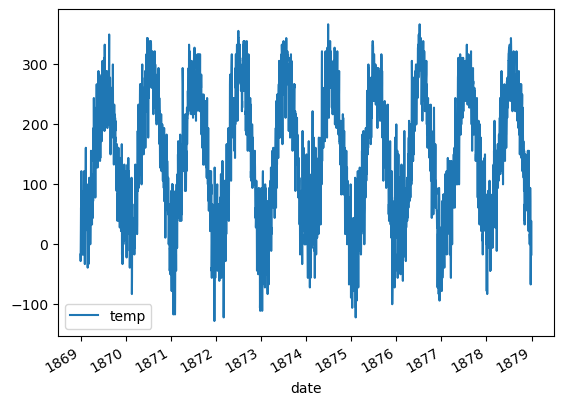

In [12]:
df.plot()

<Axes: xlabel='date'>

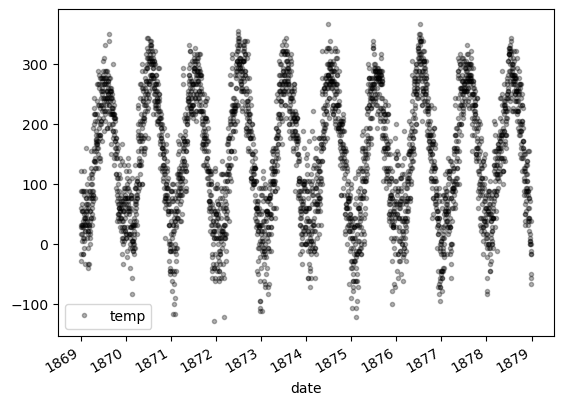

In [13]:
df.plot(style='.',color='black',alpha=0.3)

In [14]:
temp_group = df.groupby(pd.Grouper(freq='Y'))

In [15]:
temp_group.groups

{Timestamp('1869-12-31 00:00:00'): 365,
 Timestamp('1870-12-31 00:00:00'): 730,
 Timestamp('1871-12-31 00:00:00'): 1095,
 Timestamp('1872-12-31 00:00:00'): 1460,
 Timestamp('1873-12-31 00:00:00'): 1825,
 Timestamp('1874-12-31 00:00:00'): 2190,
 Timestamp('1875-12-31 00:00:00'): 2555,
 Timestamp('1876-12-31 00:00:00'): 2920,
 Timestamp('1877-12-31 00:00:00'): 3285,
 Timestamp('1878-12-31 00:00:00'): 3650}

In [16]:
keys = temp_group.groups.keys()

In [17]:
temp_group.get_group('1871-12-31')

,temp
date,
1871-01-01,39
1871-01-02,56
1871-01-03,17
1871-01-04,-11
1871-01-05,89
...,...
1871-12-27,56
1871-12-28,-56
1871-12-29,-17


In [18]:
temp_group.get_group('1871-12-31').values

array([[  39],
       [  56],
       [  17],
       [ -11],
       [  89],
       [  89],
       [   0],
       [ -61],
       [ -78],
       [ -44],
       [  11],
       [ 100],
       [  78],
       [  72],
       [  89],
       [ 100],
       [  33],
       [  17],
       [ -11],
       [  22],
       [  72],
       [  33],
       [-117],
       [ -67],
       [ -50],
       [-100],
       [  -6],
       [ -44],
       [  22],
       [  56],
       [  44],
       [  78],
       [  50],
       [  39],
       [  39],
       [-117],
       [ -89],
       [ -11],
       [   0],
       [  89],
       [  33],
       [  -6],
       [ -28],
       [ -17],
       [ -44],
       [  28],
       [  56],
       [  61],
       [ 100],
       [  44],
       [  72],
       [  56],
       [  -6],
       [  44],
       [  83],
       [ 117],
       [  89],
       [  78],
       [  44],
       [ 150],
       [ 111],
       [ 172],
       [  56],
       [ 117],
       [  94],
       [ 111],
       [  

In [19]:
years = pd.DataFrame()

for key in keys:
    years[key] = temp_group.get_group(key)
years

,1869-12-31,1870-12-31,1871-12-31,1872-12-31,1873-12-31,1874-12-31,1875-12-31,1876-12-31,1877-12-31,1878-12-31
date,,,,,,,,,,
1869-01-01,-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1869-01-02,-28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1869-01-03,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1869-01-04,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1869-01-05,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1869-12-27,78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1869-12-28,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1869-12-29,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
years.shape

(365, 10)

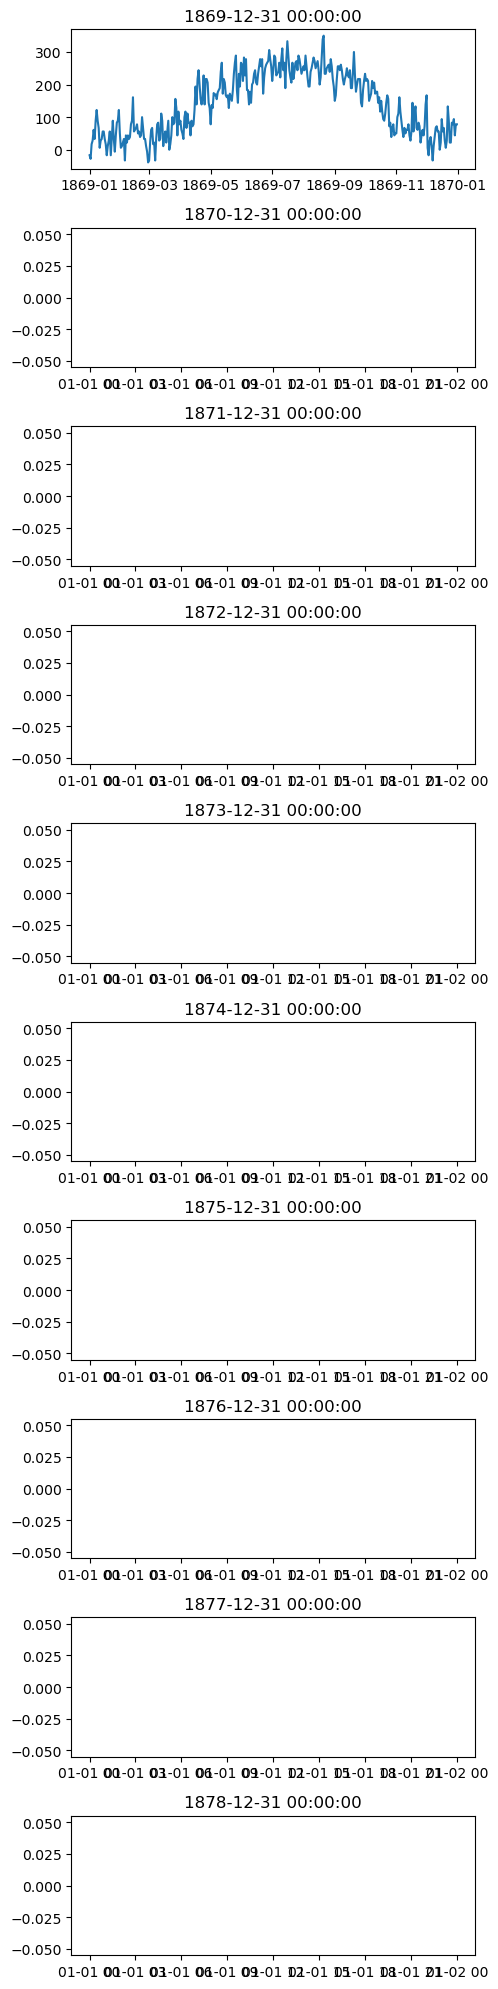

In [25]:
plt.figure(figsize=(5, 20))

color = plt.cm.tab10(np.linspace(0, 1, 10))

for i in range(10):
    plt.subplot(10, 1, i + 1)
    plt.title(years.columns[i])
    plt.plot(years.iloc[:, i], color=color[i])

plt.tight_layout()
plt.show()

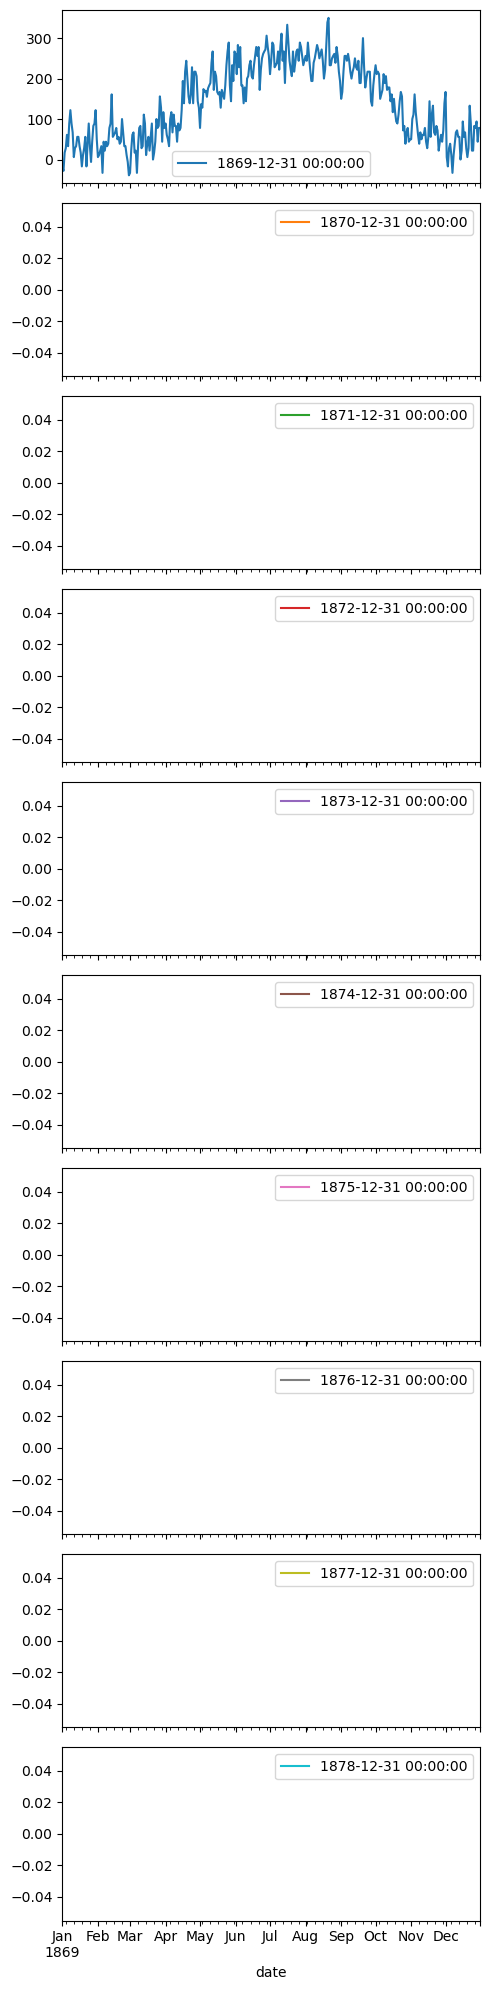

In [22]:
years.plot(subplots = True, figsize = (5,20))
plt.tight_layout()

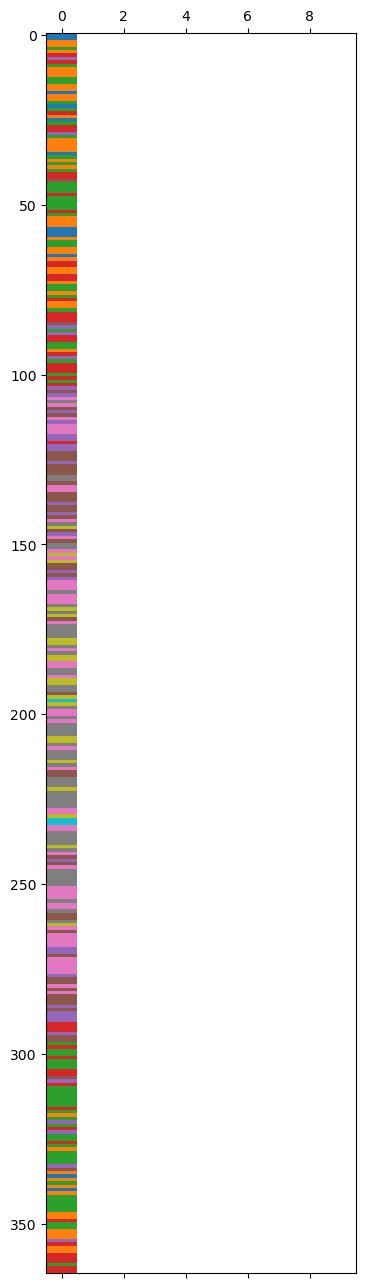

In [23]:
plt.matshow(years,aspect='auto', cmap = 'tab10')

array([[<Axes: title={'center': '1869-12-31 00:00:00'}>,
        <Axes: title={'center': '1870-12-31 00:00:00'}>,
        <Axes: title={'center': '1871-12-31 00:00:00'}>],
       [<Axes: title={'center': '1872-12-31 00:00:00'}>,
        <Axes: title={'center': '1873-12-31 00:00:00'}>,
        <Axes: title={'center': '1874-12-31 00:00:00'}>],
       [<Axes: title={'center': '1875-12-31 00:00:00'}>,
        <Axes: title={'center': '1876-12-31 00:00:00'}>,
        <Axes: title={'center': '1877-12-31 00:00:00'}>],
       [<Axes: title={'center': '1878-12-31 00:00:00'}>, <Axes: >,
        <Axes: >]], dtype=object)

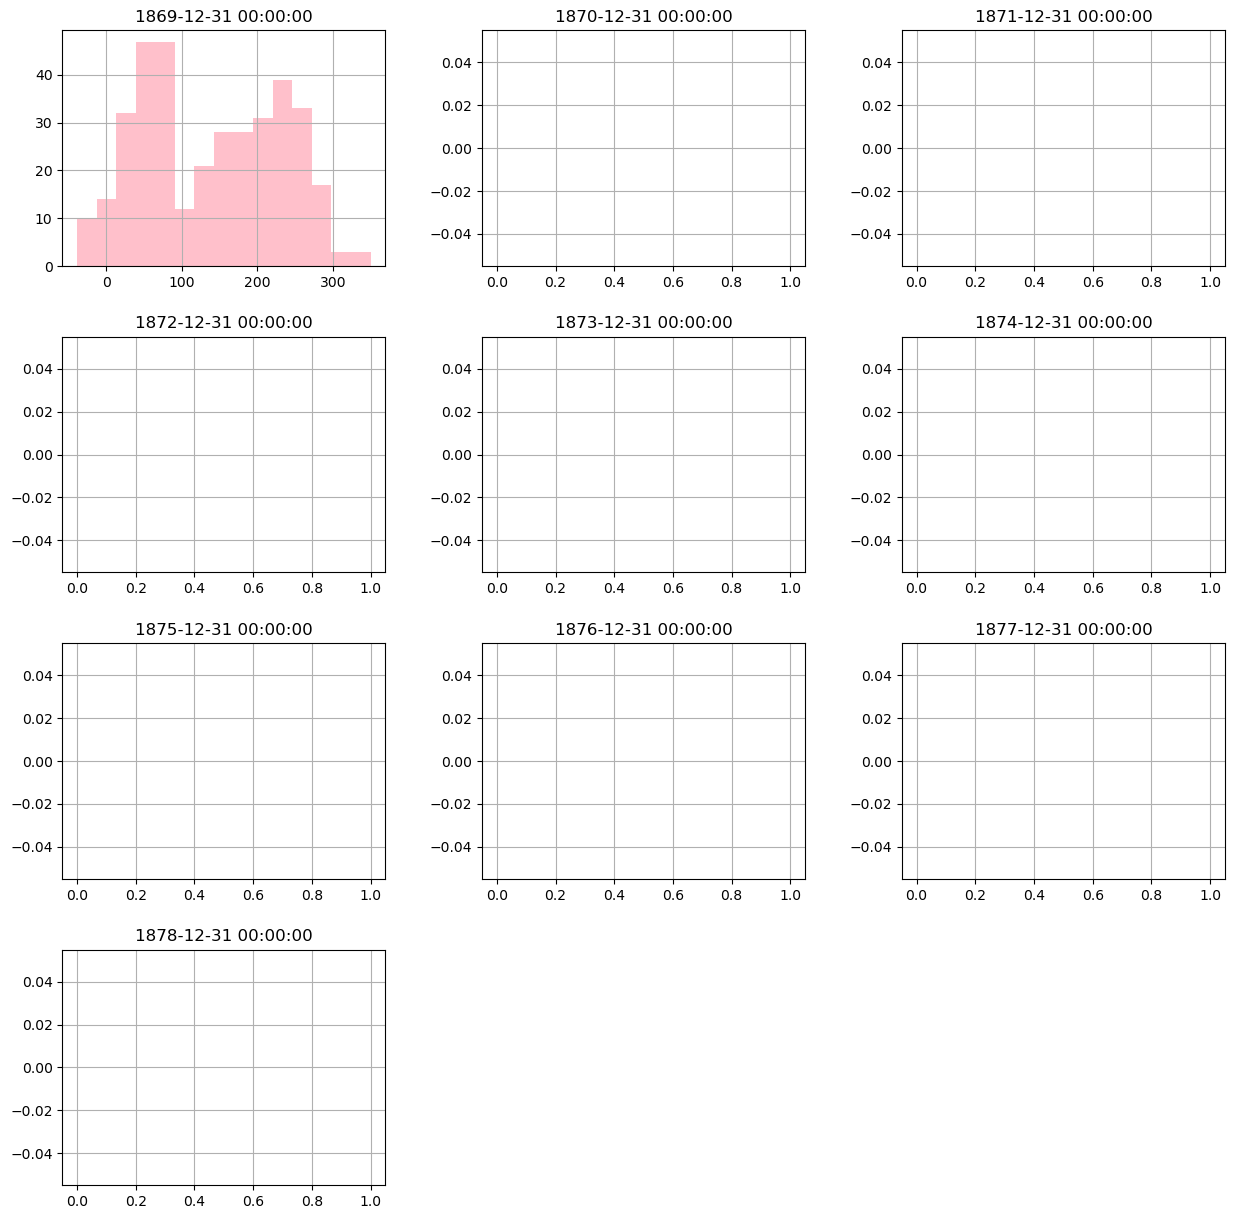

In [26]:
years.hist(figsize = (15,15), bins=15, color='pink')